In [1]:
import numpy as np
import pandas as pd

from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from src.config import DADOS_LIMPOS
from src.models import RANDOM_STATE

In [2]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
X = df.drop(columns=["Species"])
y = df["Species"]

le = LabelEncoder()

y = le.fit_transform(y)

In [4]:
y[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [5]:
le.classes_

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [6]:
le.inverse_transform([0, 1, 2])

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [8]:
np.bincount(y_train), np.bincount(y_test)

(array([40, 40, 40]), array([10, 10, 10]))

In [9]:
clf = LogisticRegression()

clf.fit(X_train, y_train)

LogisticRegression()

In [10]:
y_pred = clf.predict(X_test)

In [11]:
clf.score(X_test, y_test)

0.9666666666666667

In [12]:
confusion_matrix(y_test, y_pred)

array([[10,  0,  0],
       [ 0,  9,  1],
       [ 0,  0, 10]])

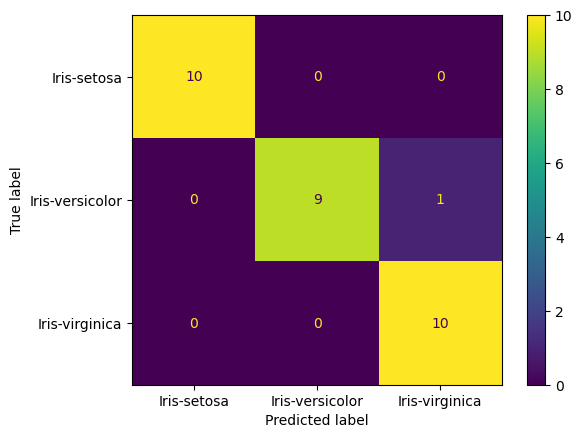

In [15]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

disp.plot()

In [16]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



#### Macro, Micro e Weighted

No contexto do Scikit-Learn, ao calcular métricas de classificação para múltiplas classes, os termos **micro**, **macro** e **weighted** referem-se às formas de calcular médias dessas métricas (como precisão, recall e f1-score). Cada uma delas faz esse cálculo de uma maneira diferente, levando em conta ou não o número de amostras em cada classe. Vamos ver o que cada uma significa:

O método **micro** realiza o cálculo das métricas globalmente, considerando todas as instâncias de todas as classes como uma só. Ele soma todos os **verdadeiros positivos**, **falsos positivos**, **verdadeiros negativos** e **falsos negativos** para todas as classes e, com base nessas somas, calcula as métricas.

- **Vantagem**: Essa média é útil quando as classes têm tamanhos significativamente diferentes, pois dá a mesma importância a cada instância (exemplo).
- **Desvantagem**: Pode mascarar o desempenho para classes menores, já que o resultado é dominado pelas classes maiores.

O método **macro** calcula a métrica de interesse (como precisão, recall ou f1-score) **individualmente** para cada classe e depois tira uma média **simples** dessas métricas, sem considerar o tamanho de cada classe.

- **Vantagem**: Dá a mesma importância a todas as classes, independentemente do número de exemplos em cada uma.
- **Desvantagem**: Se houver um grande desbalanceamento entre as classes (ou seja, algumas classes tiverem muito mais exemplos do que outras), as classes menores podem ter um impacto desproporcional na métrica final.

O método **weighted** também calcula a métrica para cada classe individualmente, mas ao fazer a média, **pesa** cada classe de acordo com seu tamanho (quantidade de exemplos no conjunto de dados).

- **Vantagem**: Considera o desbalanceamento entre as classes, ajustando a média de acordo com a importância relativa de cada classe no conjunto de dados.
- **Desvantagem**: Assim como a micro média, ela pode ocultar o desempenho de classes menores, já que classes com mais exemplos terão maior impacto na métrica final.

Resumo das Diferenças:

- **Micro**: Considera cada exemplo individualmente, somando os verdadeiros positivos, falsos positivos, etc., para todas as classes, e calcula uma única métrica.
- **Macro**: Calcula a métrica para cada classe separadamente e depois faz a média dessas métricas, dando peso igual para cada classe.
- **Weighted**: Calcula a métrica para cada classe separadamente e tira uma média ponderada de acordo com o número de exemplos em cada classe.

**Quando usar cada uma?**
- **Micro**: Ideal quando se quer ter uma visão global do desempenho do modelo, especialmente em situações com classes desbalanceadas.
- **Macro**: Útil quando você quer ver o desempenho médio do modelo para todas as classes igualmente, independentemente do tamanho.
- **Weighted**: Usado quando você deseja uma média que leve em conta o desbalanceamento de classes, mas ainda deseja ver a contribuição de todas as classes.

Imagine que temos um problema de classificação com três classes: **A**, **B** e **C**. Aqui estão as métricas para cada classe, com os seguintes valores de verdadeiros positivos (TP), falsos positivos (FP) e falsos negativos (FN) para cada classe:

| Classe | TP  | FP  | FN  | Total (Support) |
|--------|-----|-----|-----|-----------------|
| A      | 50  | 10  | 5   | 55              |
| B      | 30  | 15  | 20  | 50              |
| C      | 10  | 5   | 15  | 25              |

Agora, vamos calcular as métricas **precision**, **recall** e **f1-score** para cada classe e depois aplicar as médias **micro**, **macro** e **weighted**.

1. Cálculo Individual para Cada Classe:

**Precision (Precisão)**:
- **Classe A**: $ \frac{TP_A}{TP_A + FP_A} = \frac{50}{50 + 10} = 0.83 $
- **Classe B**: $ \frac{TP_B}{TP_B + FP_B} = \frac{30}{30 + 15} = 0.67 $
- **Classe C**: $ \frac{TP_C}{TP_C + FP_C} = \frac{10}{10 + 5} = 0.67 $

**Recall (Revocação)**:
- **Classe A**: $ \frac{TP_A}{TP_A + FN_A} = \frac{50}{50 + 5} = 0.91 $
- **Classe B**: $ \frac{TP_B}{TP_B + FN_B} = \frac{30}{30 + 20} = 0.60 $
- **Classe C**: $ \frac{TP_C}{TP_C + FN_C} = \frac{10}{10 + 15} = 0.40 $

**F1-Score** (média harmônica de precisão e recall):
- **Classe A**: $ 2 \cdot \frac{(0.83 \cdot 0.91)}{0.83 + 0.91} = 0.87 $
- **Classe B**: $ 2 \cdot \frac{(0.67 \cdot 0.60)}{0.67 + 0.60} = 0.63 $
- **Classe C**: $ 2 \cdot \frac{(0.67 \cdot 0.40)}{0.67 + 0.40} = 0.50 $

2. Micro-Average:

Para **micro-average**, somamos todos os valores de TP, FP e FN e calculamos as métricas globais:

- Total de TP = 50 (A) + 30 (B) + 10 (C) = **90**
- Total de FP = 10 (A) + 15 (B) + 5 (C) = **30**
- Total de FN = 5 (A) + 20 (B) + 15 (C) = **40**

**Micro Precision**:
$$
\text{Micro Precision} = \frac{Total\ TP}{Total\ TP + Total\ FP} = \frac{90}{90 + 30} = 0.75
$$

**Micro Recall**:
$$
\text{Micro Recall} = \frac{Total\ TP}{Total\ TP + Total\ FN} = \frac{90}{90 + 40} = 0.69
$$

**Micro F1-Score**:
$$
\text{Micro F1} = 2 \cdot \frac{(0.75 \cdot 0.69)}{0.75 + 0.69} = 0.72
$$

3. Macro-Average:

Para **macro-average**, calculamos a média simples das métricas de cada classe:

**Macro Precision**:
$$
\text{Macro Precision} = \frac{0.83 + 0.67 + 0.67}{3} = 0.72
$$

**Macro Recall**:
$$
\text{Macro Recall} = \frac{0.91 + 0.60 + 0.40}{3} = 0.64
$$

**Macro F1-Score**:
$$
\text{Macro F1} = \frac{0.87 + 0.63 + 0.50}{3} = 0.67
$$

4. Weighted-Average:

Para **weighted-average**, calculamos a média ponderada de cada métrica, levando em conta o número de exemplos (support) de cada classe. A ponderação é feita pelo suporte (o número de exemplos) de cada classe.

**Weighted Precision**:
$$
\text{Weighted Precision} = \frac{(0.83 \times 55) + (0.67 \times 50) + (0.67 \times 25)}{55 + 50 + 25} = 0.75
$$

**Weighted Recall**:
$$
\text{Weighted Recall} = \frac{(0.91 \times 55) + (0.60 \times 50) + (0.40 \times 25)}{55 + 50 + 25} = 0.72
$$

**Weighted F1-Score**:
$$
\text{Weighted F1} = \frac{(0.87 \times 55) + (0.63 \times 50) + (0.50 \times 25)}{55 + 50 + 25} = 0.73
$$

Comparação dos Resultados:

| Tipo      | Precision | Recall | F1-Score |
|-----------|-----------|--------|----------|
| Micro     | 0.75      | 0.69   | 0.72     |
| Macro     | 0.72      | 0.64   | 0.67     |
| Weighted  | 0.75      | 0.72   | 0.73     |

Interpretação:

- A **média micro** pondera cada instância igualmente, resultando em métricas que refletem o desempenho global, independentemente do desbalanceamento de classes.
- A **média macro** trata cada classe igualmente, o que pode subestimar o desempenho em classes com muitos exemplos e exagerar o impacto das classes menores.
- A **média weighted** ajusta as métricas considerando o número de exemplos em cada classe, refletindo melhor o impacto de classes maiores.

Esses diferentes tipos de média são úteis dependendo do foco da análise. Para conjuntos de dados desbalanceados, a **média ponderada** é frequentemente preferida, enquanto a **média macro** é boa para comparar o desempenho entre classes igualmente.

## Visualizando os limites de decisão de um classificador 

In [18]:
X_2d = X[["PetalLengthCm", "PetalWidthCm"]]

X_train, X_test, y_train, y_test = train_test_split(
    X_2d, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

clf = LogisticRegression()

clf.fit(X_train, y_train)

LogisticRegression()

In [20]:
clf.score(X_test, y_test)

0.9666666666666667

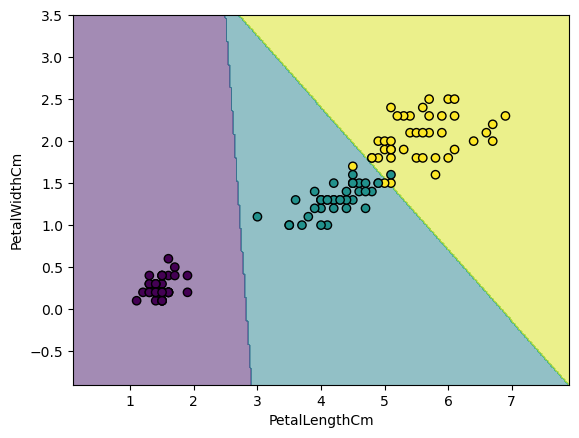

In [ ]:
disp = DecisionBoundaryDisplay.from_estimator(
    clf, X_train, grid_resolution=300, alpha=0.5
)

disp.ax_.scatter(X_train["PetalLengthCm"], X_train["PetalWidthCm"], c=y_train, edgecolors="black")